# Разведочный анализ данных (EDA) и проверка гипотез (ДЗ 2–3)

**Кейс:** Исследование продаж и факторов, влияющих на динамику выручки в розничной торговле.  
**Цель ноутбука:** провести целевой EDA на очищенной витрине данных, проверить сопоставимость промо-показателей (`MarkDown1–5` по рекомендации ментора), изучить сезонность, праздничные пики и разрезы по форматам магазинов (защита от смешения сегментов), а также статистически проверить 3 утверждённые с заказчиком гипотезы.

---

### Приоритетные гипотезы (согласованы с заказчиком)

1. **Гипотеза 1 (Эффективность промо-акций):**  
   * **Формулировка:** В непраздничные недели (`IsHoliday == False`) медианная недельная выручка в периоды проведения промо-акций статистически значимо выше, чем в недели без акций, не менее чем на **+10% (MDE)**, при этом сила связи с выручкой различается в зависимости от канала `MarkDown1–5`.
   * **Бизнес-обоснование:** Позволит отделить реальный эффект скидок от естественного сезонного фона и выявить наиболее результативные каналы `MarkDown` для перераспределения промо-бюджета.
   * **Критерий опровержения:** Отвергается, если в непраздничные недели выручка при наличии акций статистически не отличается от выручки без акций ($p \ge 0.05$) или медианный прирост составляет **менее +10% (MDE)**.

2. **Гипотеза 2 (Сезонные и праздничные пики):**  
   * **Формулировка:** Недельная выручка имеет выраженную годовую сезонность: в праздничные недели (`IsHoliday == True`) и за 1–2 недели до ключевых пиков (День благодарения, Рождество) медианная выручка возрастает не менее чем на **+15% (MDE)** относительно базового уровня года, а в последующие 1–2 недели (`Post-Holiday`) наблюдается статистически значимый спад не менее чем на **-10% (MDE)**.
   * **Бизнес-обоснование:** Поможет точнее планировать товарные запасы и график персонала как к пиковым неделям, так и к постпраздничному спаду, предотвращая затоваривание.
   * **Критерий опровержения:** Отвергается, если праздничный рост составляет **менее +15%** или в постпраздничные 1–2 недели не наблюдается статистически значимого спада от **-10% (MDE)** относительно базового уровня года ($p \ge 0.05$).

3. **Гипотеза 3 (Различия между форматами магазинов):**  
   * **Формулировка:** Относительный прирост выручки (в %) в периоды промо-акций и праздничных пиков статистически значимо различается между форматами магазинов (`Type A`, `B`, `C`) не менее чем на **5 п.п. (MDE)** и положительно связан с площадью магазина (`Size`).
   * **Бизнес-обоснование:** Позволит дифференцировать промо-стратегию и управление товарными запасами между крупными гипермаркетами (`A`), средними (`B`) и малыми точками (`C`).
   * **Критерий опровержения:** Отвергается, если различия в относительном приросте выручки между форматами `A/B/C` статистически незначимы ($p \ge 0.05$) или меньше **5 п.п. (MDE)**, а корреляция прироста с площадью `Size` близка к нулю ($|r| < 0.1$).

---

### Отложенные и непроверяемые гипотезы (с обоснованием)

* **Отложенные (по согласованию с заказчиком):**
  1. *Анализ возвратов (`Weekly_Sales < 0`):* заказчик подтвердил приоритет динамики продаж над возвратами; вернёмся к ним при необходимости.
  2. *Влияние погоды и макроэкономики (`Temperature`, `Fuel_Price`, `CPI`, `Unemployment`):* на эти факторы бизнес не может повлиять при планировании акций; отложено до отдельного запроса заказчика.
  3. *Поведенческая кластеризация отделов:* выделена как второстепенная задача после проверки трёх основных гипотез.
* **Непроверяемые (ограничения данных):**
  1. *Сегментация клиентов:* в датасете отсутствует `Customer ID`; фокус перенесён на сегментацию магазинов и отделов.
  2. *Зависимость выручки от региона:* в таблице `stores` нет признака региона; заказчик подтвердил снятие регионального разреза.

---

### План работы в ноутбуке
1. **Сборка витрины данных** и генерация согласованных с заказчиком признаков (`Is_MarkDown_Period`, `Has_MarkDown_Data`, `Has_Neg_MarkDown`, `Total_MarkDown`, `Has_MarkDown`).
2. **Блок 1 (рекомендация ментора):** анализ распределений и масштабов `MarkDown1–5` по отдельности, оценка сопоставимости.
3. **Блок 2:** распределение целевой переменной `Weekly_Sales`, временная динамика и праздничные пики.
4. **Блок 3:** анализ сегментов — форматы магазинов (`Type A/B/C`), профили отделов (`Dept`), двухуровневые корреляции и многофакторная регрессия (OLS).
5. **Блок 4:** прямая статистическая проверка гипотез **H1, H2, H3** с анализом чувствительности и итоговыми вердиктами.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

stores = pd.read_csv(r"C:\Users\jacob\Downloads\data\stores_data_set.csv")
features = pd.read_csv(r"C:\Users\jacob\Downloads\data\Features_data_set.csv")
sales = pd.read_csv(r"C:\Users\jacob\Downloads\data\sales_data_set.csv")

In [2]:
stores.head()

,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875


In [3]:
features.head()

,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,05/02/2010,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,12/02/2010,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,19/02/2010,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,26/02/2010,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,05/03/2010,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


In [4]:
sales.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,05/02/2010,24924.50,False
1,1,1,12/02/2010,46039.49,True
2,1,1,19/02/2010,41595.55,False
3,1,1,26/02/2010,19403.54,False
4,1,1,05/03/2010,21827.90,False


In [5]:
# Приведение дат и объединение
features["Date"] = pd.to_datetime(features["Date"], format="%d/%m/%Y")
sales["Date"] = pd.to_datetime(sales["Date"], format="%d/%m/%Y")

df = (
    sales
    .merge(features, on=["Store", "Date", "IsHoliday"], how="left")
    .merge(stores, on="Store", how="left")
)

In [6]:
df.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,A,151315


In [7]:
# Календарные и промо-признаки (по правилам заказчика)
md_cols = ["MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5"]

df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Week"] = df["Date"].dt.isocalendar().week.astype(int)
df["Temp_C"] = ((df["Temperature"] - 32) * 5 / 9).round(1)

df["Is_MarkDown_Period"] = (df["Date"] >= "2011-11-11").astype("int8")
df["Has_MarkDown_Data"] = df[md_cols].notna().any(axis=1).astype("int8")
df["Has_Neg_MarkDown"] = (df[md_cols] < 0).any(axis=1).astype("int8")

In [8]:
df["Is_MarkDown_Period"].sum()

np.int64(151432)

In [9]:
df["Has_MarkDown_Data"].sum()

np.int64(151432)

In [10]:
df["Has_Neg_MarkDown"].sum()

np.int64(1568)

In [11]:
df["Total_MarkDown"] = np.where(
    df["Has_MarkDown_Data"] == 1,
    df[md_cols].clip(lower=0).sum(axis=1, skipna=True),
    np.nan
)
df["Has_MarkDown"] = np.where(
    df["Has_MarkDown_Data"] == 1,
    (df["Total_MarkDown"] > 0).astype(int),
    np.nan
)

print(f"Витрина собрана: {df.shape[0]:,} строк | {df.shape[1]:,} столбцов")

Витрина собрана: 421,570 строк | 25 столбцов


In [12]:
df.head(-1)

,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,...,Size,Year,Month,Week,Temp_C,Is_MarkDown_Period,Has_MarkDown_Data,Has_Neg_MarkDown,Total_MarkDown,Has_MarkDown
0,1,1,2010-02-05,24924.50,False,42.31,2.572,NaN,NaN,NaN,...,151315,2010,2,5,5.7,0,0,0,NaN,NaN
1,1,1,2010-02-12,46039.49,True,38.51,2.548,NaN,NaN,NaN,...,151315,2010,2,6,3.6,0,0,0,NaN,NaN
2,1,1,2010-02-19,41595.55,False,39.93,2.514,NaN,NaN,NaN,...,151315,2010,2,7,4.4,0,0,0,NaN,NaN
3,1,1,2010-02-26,19403.54,False,46.63,2.561,NaN,NaN,NaN,...,151315,2010,2,8,8.1,0,0,0,NaN,NaN
4,1,1,2010-03-05,21827.90,False,46.50,2.625,NaN,NaN,NaN,...,151315,2010,3,9,8.1,0,0,0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
421564,45,98,2012-09-21,467.30,False,65.32,4.038,8452.20,92.28,63.24,...,118221,2012,9,38,18.5,1,1,0,19654.50,1.0
421565,45,98,2012-09-28,508.37,False,64.88,3.997,4556.61,20.64,1.50,...,118221,2012,9,39,18.3,1,1,0,9468.01,1.0
421566,45,98,2012-10-05,628.10,False,64.89,3.985,5046.74,NaN,18.82,...,118221,2012,10,40,18.3,1,1,0,9659.00,1.0
421567,45,98,2012-10-12,1061.02,False,54.47,4.000,1956.28,NaN,7.89,...,118221,2012,10,41,12.5,1,1,0,6554.03,1.0


## Добавленные признаки
- **Size** — размер магазина (площадь торгового зала в квадратных футах). Помогает учитывать масштаб точки при анализе выручки и объёма скидок.
- **Year** — год
- **Month** — номер месяца в году
- **Week** — номер недели в году
- **Temp_C** — температура воздуха в градусах Цельсия
- **Is_MarkDown_Period** — флаг периода действия промо-скидок (1, если дата записи >= 2011-11-11, иначе 0). Отделяет историю до появления данных об уценках от периода, когда они начали фиксироваться.
- **Has_MarkDown_Data** — флаг наличия данных об уценках (1, если хотя бы в одном столбце из md_cols не NaN, иначе 0). Показывает, есть ли в строке вообще информация о скидках.
- **Has_Neg_MarkDown** — флаг отрицательных скидок (1, если хотя бы в одном столбце md_cols значение < 0, иначе 0). Сигнализирует о возвратах, корректировках или ошибках в данных по уценкам.
- **Total_MarkDown** — суммарная положительная скидка по всем столбцам md_cols за строку (с предварительным обрезанием отрицательных значений до 0). Заполняется только там, где Has_MarkDown_Data == 1, а в строках без данных по скидкам остаётся NaN.
- **Has_MarkDown** — флаг фактического наличия положительной скидки (1.0, если Total_MarkDown > 0; 0.0, если данные по скидкам присутствовали, но итоговая сумма равна 0; NaN, если данных о скидках вообще нет).

### Блок 1. Распределения и сопоставимость `MarkDown1–5` (рекомендация ментора)
Перед агрегацией промо-показателей в единый `Total_MarkDown` проверим каждый канал уценок по отдельности на уровне уникальных недель и магазинов (`features` в периоде продаж, где `Has_MarkDown_Data == 1`), чтобы не искажать статистики размножением строк по 81 отделу.

**Что проверяем:**
* заполненность каждого канала (`MarkDown1–5`);
* порядки величин (медианы, квантили 25% / 75% / 95%, максимумы) — сопоставимы ли масштабы;
* долю и влияние отрицательных значений (`Has_Neg_MarkDown`).

In [13]:
# Берём уникальные пары (Store, Date) из периода продаж, где есть хотя бы один заполненный MarkDown
md_sample = df[df["Has_MarkDown_Data"] == 1][["Store", "Date", "IsHoliday", "Has_Neg_MarkDown"] + md_cols].drop_duplicates()

print(f"Уникальных магазин-недель с доступными данными MarkDown: {len(md_sample):,}")
print(
    f"Из них с отрицательными значениями (Has_Neg_MarkDown == 1): "
    f"{md_sample['Has_Neg_MarkDown'].sum()} ({md_sample['Has_Neg_MarkDown'].mean():.2%})"
)

Уникальных магазин-недель с доступными данными MarkDown: 2,295
Из них с отрицательными значениями (Has_Neg_MarkDown == 1): 23 (1.00%)


In [14]:
# Сводная таблица статистик по каждому каналу отдельно (на положительных/неотрицательных значениях)
stats_list = []
for col in md_cols:
    s = md_sample[col].dropna()
    s_pos = s[s > 0]
    stats_list.append({
        "Канал": col,
        "Заполнено (недель)": len(s),
        "Доля заполнения (%)": round(len(s) / len(md_sample) * 100, 1),
        "Отриц. (шт.)": (s < 0).sum(),
        "Мин.": round(s.min(), 2),
        "Медиана (P50)": round(s_pos.median(), 2),
        "P75": round(s_pos.quantile(0.75), 2),
        "P95": round(s_pos.quantile(0.95), 2),
        "Макс.": round(s_pos.max(), 2),
    })

md_stats_df = pd.DataFrame(stats_list)
display(md_stats_df)

,Канал,Заполнено (недель),Доля заполнения (%),Отриц. (шт.),Мин.,Медиана (P50),P75,P95,Макс.
0,MarkDown1,2280,99.3,0,0.27,4972.59,8873.58,21290.95,88646.76
1,MarkDown2,1637,71.3,19,-265.76,193.94,1882.54,15241.56,104519.54
2,MarkDown3,2046,89.2,4,-29.10,22.92,100.00,1018.94,141630.61
3,MarkDown4,1965,85.6,0,0.22,1419.42,3496.08,12181.70,67474.85
4,MarkDown5,2295,100.0,0,135.16,3186.52,5422.08,10675.38,108519.28


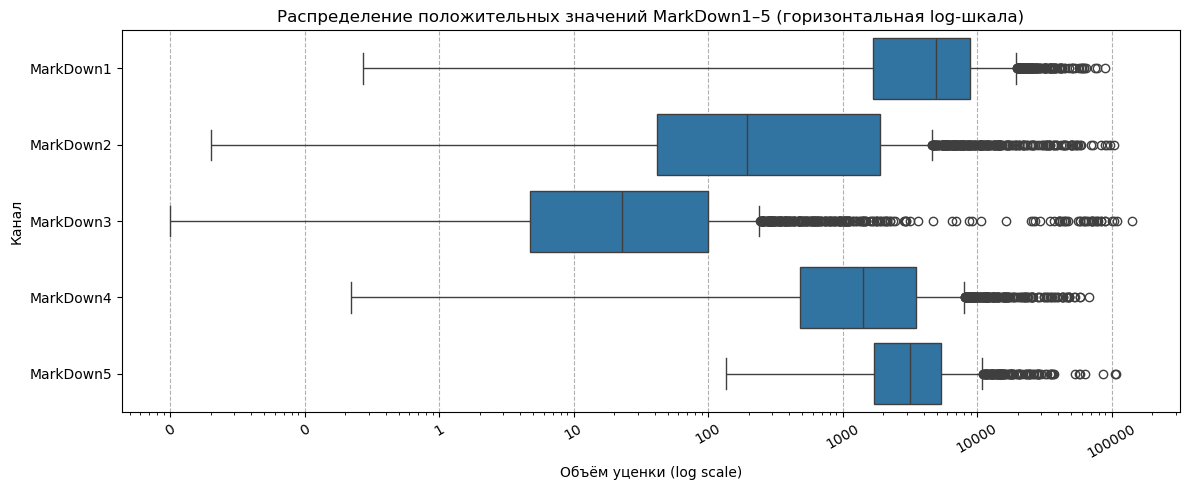

In [15]:
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import seaborn as sns

fig, ax = plt.subplots(figsize=(12, 5))

md_melted = md_sample[md_cols].melt(var_name="Канал", value_name="Значение")
md_melted = md_melted[md_melted["Значение"] > 0]

# Меняем x и y местами: значения — по горизонтали (X), каналы — по вертикали (Y)
sns.boxplot(
    data=md_melted,
    x="Значение",
    y="Канал",
    order=md_cols,  # сохраняем порядок MarkDown1 -> MarkDown5 сверху вниз
    ax=ax,
)

# Логарифмическая шкала по горизонтальной оси
ax.set_xscale("log")

# Обычный числовой формат подписей вместо 10^2, 10^4 и т.д. (при необходимости можно оставить log)
formatter = ScalarFormatter()
formatter.set_scientific(False)
ax.xaxis.set_major_formatter(formatter)

# Поворот подписей по X на случай плотных значений и сетка для удобного считывания
ax.tick_params(axis="x", rotation=30)
ax.grid(axis="x", linestyle="--", alpha=0.99)

ax.set_title(
    "Распределение положительных значений MarkDown1–5 (горизонтальная log-шкала)"
)
ax.set_xlabel("Объём уценки (log scale)")
ax.set_ylabel("Канал")

plt.tight_layout()
plt.show()

#### Вывод по Блоку 1: сопоставимость промо-каналов `MarkDown1–5`

1. **Наблюдение:** на логарифмическом графике распределений видны три разные группы масштабов:
   * `MarkDown1`, `MarkDown4` и `MarkDown5` лежат в высоком и компактном диапазоне с медианами порядка $10^3\text{–}10^4$ у.е.;
   * `MarkDown2` ниже на порядок (медиана $\approx 2 \cdot 10^2$ у.е.) и имеет широкий межквартильный размах;
   * `MarkDown3` обладает самой низкой медианой ($\approx 20$ у.е.), но самым длинным хвостом выбросов вверх, превышающим $10^5$ у.е.
2. **Возможная интерпретация:** показатели измеряются в сопоставимых условных единицах бюджета уценок, но отражают принципиально разные типы акций — регулярные масштабные промо (`MarkDown1, 4, 5`) и точечные/событийные распродажи (`MarkDown2, 3`), которые выстреливают в пиковые недели (например, в Чёрную пятницу).
3. **Влияние на гипотезы и дальнейший анализ:** простое суммирование в `Total_MarkDown` без оговорок маскирует влияние `MarkDown2` и `MarkDown3` в обычные недели за счёт более крупных каналов. Поэтому при проверке гипотез и построении регрессии необходимо оценивать вклад каждого канала `MarkDown1–5` по отдельности, а `Total_MarkDown` использовать только как вспомогательный агрегат.
4. **Ограничения уверенности:** доля отрицательных значений в выборке составляет менее 1%; при тестировании гипотез проведём анализ чувствительности (сравним результаты при полном исключении этих недель и при их обнулении).


### Блок 2. Целевая переменная `Weekly_Sales`, сезонность и праздничные пики
Изучим распределение недельных продаж, динамику выручки сети за 2010–2012 гг., величину праздничных скачков (`IsHoliday`) и распределение возвратов (`Weekly_Sales < 0`).

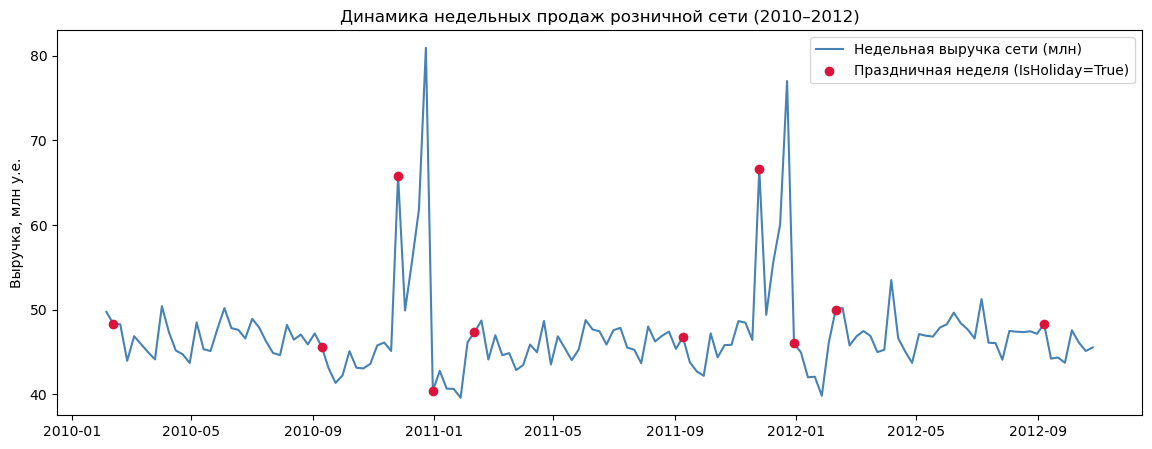

In [16]:
# 1. Динамика суммарной выручки сети по неделям с отметкой праздников
weekly_total = df.groupby(["Date", "IsHoliday"], as_index=False)["Weekly_Sales"].sum()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(weekly_total["Date"], weekly_total["Weekly_Sales"] / 1e6, label="Недельная выручка сети (млн)", color="steelblue")
holidays = weekly_total[weekly_total["IsHoliday"]]
ax.scatter(holidays["Date"], holidays["Weekly_Sales"] / 1e6, color="crimson", zorder=5, label="Праздничная неделя (IsHoliday=True)")
ax.set_title("Динамика недельных продаж розничной сети (2010–2012)")
ax.set_ylabel("Выручка, млн у.е.")
ax.legend()
plt.show()

In [17]:
# 2. Сравнение продаж и доли возвратов в праздничные и обычные недели (уровень: магазин — отдел — неделя)
holiday_stats = df.groupby("IsHoliday")["Weekly_Sales"].agg(
    Наблюдений="count",
    Среднее="mean",
    Медиана="median",
    P25=lambda x: x.quantile(0.25),
    P75=lambda x: x.quantile(0.75),
    Доля_возвратов_pct=lambda x: (x < 0).mean() * 100
).round(2)
display(holiday_stats)

,Наблюдений,Среднее,Медиана,P25,P75,Доля_возвратов_pct
IsHoliday,,,,,,
False,391909,15901.45,7589.95,2079.75,20131.21,0.30
True,29661,17035.82,7947.74,2078.54,21189.25,0.33


#### Вывод по Блоку 2: временная динамика, праздничные пики и возвраты

1. **Наблюдение:** на графике общей выручки сети видна выраженная годовая сезонность с резкими пиками в ноябре–декабре (День благодарения / Чёрная пятница и Рождество). Однако на уровне «магазин — отдел — неделя» медианная выручка в официальные праздничные недели (`IsHoliday=True`) выше обычных недель всего на **+4.7%** ($7\,947.74$ против $7\,589.95$ у.е.), а доля возвратов слегка возрастает с **0.30%** до **0.33%**.
2. **Возможная интерпретация:** декабрьский предрождественский пик (середина декабря) не помечен флагом `IsHoliday=True` (в датасете этим флагом отмечены только 4 конкретные недели в году: Супербоул, День труда, День благодарения и Рождество), а реакция на праздники сильно зависит от категории товара.
3. **Влияние на гипотезы и дальнейший анализ:** проверять влияние праздников только в среднем по всей сети некорректно (разные отделы тянут метрику в разные стороны). Необходимо разделить отделы на поведенческие сегменты и дополнительно проверить предпраздничные недели (включая декабрьский пик).
4. **Ограничения уверенности:** сильная правосторонняя асимметрия выручки (среднее более чем в 2 раза выше медианы) делает классическое сравнение средних чувствительным к выбросам — при проверке гипотез используем непараметрический критерий Манна — Уитни и сравнение медиан.


### Блок 3. Разрезы по сегментам: форматы магазинов (`Type`) и профили отделов (`Dept`)
Чтобы избежать ловушки смешения сегментов (парадокс Симпсона), проверим, как различаются базовые продажи, возвраты и реакция на праздники по типам магазинов (`A`, `B`, `C`) и сформируем поведенческий профиль каждого отдела (`Dept`) для последующей кластеризации.

In [18]:
# 1. Сравнение форматов магазинов (Type A, B, C)
type_stats = df.groupby("Type").agg(
    Магазинов=("Store", "nunique"),
    Средняя_площадь=("Size", "mean"),
    Медиана_выручки_отдела=("Weekly_Sales", "median"),
    Средняя_выручка_отдела=("Weekly_Sales", "mean"),
    Доля_возвратов_pct=("Weekly_Sales", lambda x: (x < 0).mean() * 100)
).round(2)
print("Сравнение форматов магазинов:")
display(type_stats)

Сравнение форматов магазинов:


,Магазинов,Средняя_площадь,Медиана_выручки_отдела,Средняя_выручка_отдела,Доля_возвратов_pct
Type,,,,,
A,22,182231.29,10105.17,20099.57,0.23
B,17,101818.74,6187.87,12237.08,0.41
C,6,40535.73,1149.67,9519.53,0.29


In [19]:
# Проверка количества активных отделов в магазинах разных форматов
depts_per_store = df.groupby(["Type", "Store"], as_index=False)["Dept"].nunique()
display(depts_per_store.groupby("Type")["Dept"].agg(["count", "mean", "median", "min", "max"]).round(1))

,count,mean,median,min,max
Type,,,,,
A,22,76.0,77.0,63,79
B,17,75.6,76.0,72,79
C,6,62.3,62.0,61,64


In [20]:
# 2. Формирование поведенческого профиля отделов (база для гипотезы по сегментации отделов)
dept_profiles = df.groupby("Dept").agg(
    Наблюдений=("Weekly_Sales", "count"),
    Медиана_выручки=("Weekly_Sales", "median"),
    Средняя_выручка=("Weekly_Sales", "mean"),
    Коэф_вариации=("Weekly_Sales", lambda x: x.std() / x.mean() if x.mean() != 0 else np.nan),
    Доля_возвратов_pct=("Weekly_Sales", lambda x: (x < 0).mean() * 100)
).round(2)

In [21]:
# Добавим относительный праздничный прирост (Holiday Lift) по каждому отделу
hol_pivot = df.pivot_table(index="Dept", columns="IsHoliday", values="Weekly_Sales", aggfunc="median")
dept_profiles["Holiday_Lift_pct"] = ((hol_pivot[True] - hol_pivot[False]) / hol_pivot[False] * 100).round(1)

print("\nТоп-10 отделов по медианной выручке и их поведенческие метрики:")
display(dept_profiles.sort_values("Медиана_выручки", ascending=False).head(10))


Топ-10 отделов по медианной выручке и их поведенческие метрики:


,Наблюдений,Медиана_выручки,Средняя_выручка,Коэф_вариации,Доля_возвратов_pct,Holiday_Lift_pct
Dept,,,,,,
92,6435,61816.77,75204.87,0.66,0.00,5.2
95,6435,60774.39,69824.42,0.55,0.00,-5.9
38,6435,57336.65,61090.62,0.39,0.00,-6.5
65,143,47281.16,45441.71,0.16,0.00,-17.1
72,6046,44312.36,50566.52,0.88,0.56,43.0
40,6435,42717.87,44900.70,0.49,0.00,-0.2
2,6435,41412.61,43607.02,0.58,0.00,-7.5
90,6435,40535.79,45232.08,0.72,0.00,3.8
94,5685,35003.70,33405.88,0.76,1.35,-2.5


#### Вывод по Блоку 3: форматы магазинов (`Type`) и смешение сегментов в отделах (`Dept`)

1. **Наблюдение:** 
   * Форматы магазинов чётко ранжируются по площади и медианной выручке отдела: `Type A` ($10\,105.17$ у.е., возвраты **0.23%**), `Type B` ($6\,187.87$ у.е., максимальная доля возвратов — **0.41%**), `Type C` ($1\,149.67$ у.е., возвраты **0.29%**). При этом в `Type C` среднее ($9\,519.53$) в 8.3 раза выше медианы.
   * На уровне отделов обнаружен яркий **эффект смешения сегментов**: у отделов (`Dept 95, 38, 2`) медианный праздничный прирост отрицательный (**-5.9%**, **-6.5%**, **-7.5%**), тогда как у отдела `Dept 72` он достигает **+43.0%** (при доле возвратов **0.56%**). Отдел `Dept 65` присутствует только в 1 магазине из 45 (143 наблюдения).
   * В форматах Type A и B в среднем работает по 76 отделов, тогда как в малых точках Type C — только 62.3 отдела.
2. **Возможная интерпретация:** малые точки (`Type C`) имеют усечённую ассортиментную матрицу (высокий оборот в нескольких базовых отделах и минимальный в остальных), а в праздники покупательский бюджет перераспределяется из повседневных категорий в подарочные и сезонные товары.
3. **Влияние на гипотезы и дальнейший анализ:** считать эффекты в среднем по всей сети нельзя — разные типы магазинов и отделов ведут себя противоположно и гасят друг друга. Поэтому при постановке гипотез и проверке акций (`MarkDown`) мы будем делить данные по форматам точек (`Type A/B/C`) и сегментам отделов (`Dept`), а не смотреть общую среднюю по всем 45 магазинам.
4. **Ограничения уверенности:** неравномерное присутствие отделов в разных магазинах (несбалансированная панель) требует учёта числа активных отделов при сравнении магазинов между собой.


In [22]:
df_check_corr = df[['Year', 'Month', 'Week', 'Store', 'Dept', 'Type', 'Size', 'Weekly_Sales', 'IsHoliday', 'Fuel_Price', 'Temp_C', 'CPI', 'Unemployment'] + md_cols]
display(df_check_corr)

,Year,Month,Week,Store,Dept,Type,Size,Weekly_Sales,IsHoliday,Fuel_Price,Temp_C,CPI,Unemployment,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5
0,2010,2,5,1,1,A,151315,24924.50,False,2.572,5.7,211.096358,8.106,NaN,NaN,NaN,NaN,NaN
1,2010,2,6,1,1,A,151315,46039.49,True,2.548,3.6,211.242170,8.106,NaN,NaN,NaN,NaN,NaN
2,2010,2,7,1,1,A,151315,41595.55,False,2.514,4.4,211.289143,8.106,NaN,NaN,NaN,NaN,NaN
3,2010,2,8,1,1,A,151315,19403.54,False,2.561,8.1,211.319643,8.106,NaN,NaN,NaN,NaN,NaN
4,2010,3,9,1,1,A,151315,21827.90,False,2.625,8.1,211.350143,8.106,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
421565,2012,9,39,45,98,B,118221,508.37,False,3.997,18.3,192.013558,8.684,4556.61,20.64,1.50,1601.01,3288.25
421566,2012,10,40,45,98,B,118221,628.10,False,3.985,18.3,192.170412,8.667,5046.74,NaN,18.82,2253.43,2340.01
421567,2012,10,41,45,98,B,118221,1061.02,False,4.000,12.5,192.327265,8.667,1956.28,NaN,7.89,599.32,3990.54
421568,2012,10,42,45,98,B,118221,760.01,False,3.969,13.6,192.330854,8.667,2004.02,NaN,3.18,437.73,1537.49


#### Этот блок задаёт единую базу перед расчётами, чтобы не дублировать логику в разных местах:

    -- Безопасная копия (df_a = df_check_corr.copy()): исходная таблица df_check_corr остаётся нетронутой, а все преобразования идут в df_a.

    -- Приведение IsHoliday к числам (0 / 1): если флаг хранится как текст ("True" / "False"), он сначала приводится к нижнему регистру и отображается в булевы значения, а затем .astype(int) превращает True в 1 и False в 0. Так с признаком удобно работать и в корреляциях, и в регрессии.

    -- Динамический список md_present: отбирает из возможных колонок MarkDown1–MarkDown5 только те, которые реально присутствуют в df_check_corr — код не упадёт с KeyError, если какой-то канал не добавлялся.

    Функция calc_corrs(data, target_col, cols):
    - Приводит целевой столбец и каждый признак к числовому виду через pd.to_numeric(..., errors="coerce"), чтобы случайные текстовые значения или пропуски не ломали вычисления.
    - Делает попарный dropna() по паре (x, y) — благодаря этому пропуски в одном столбце (например, в MarkDown2 или MarkDown5) не выбрасывают строки при оценке других признаков.
    - Проверяет, что наблюдений больше двух и признак не константен (nunique() > 1), после чего считает корреляцию Пирсона (линейная связь и чувствительность к выбросам) и корреляцию Спирмена (монотонная ранговая связь, устойчивая к перекосам и пикам) вместе с p-value.
    - Сортирует результат по убыванию модуля spearman_rho (key=abs, ascending=False), чтобы самые сильные связи были сверху.

In [23]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm

df_a = df_check_corr.copy()

# Приводим IsHoliday к числовому виду (0/1)
if df_a["IsHoliday"].dtype == object:
  df_a["IsHoliday"] = (
      df_a["IsHoliday"].astype(str).str.lower().map({"true": True, "false": False})
  )
df_a["IsHoliday_int"] = df_a["IsHoliday"].astype(int)

md_present = [
    c
    for c in [
        "MarkDown1",
        "MarkDown2",
        "MarkDown3",
        "MarkDown4",
        "MarkDown5",
    ]
    if c in df_a.columns
]


def calc_corrs(data, target_col, cols):
  out = []
  y_all = pd.to_numeric(data[target_col], errors="coerce")
  for c in cols:
    x_all = pd.to_numeric(data[c], errors="coerce")
    sub = pd.DataFrame({"x": x_all, "y": y_all}).dropna()
    if len(sub) > 2 and sub["x"].nunique() > 1:
      r_p, p_p = stats.pearsonr(sub["x"], sub["y"])
      r_s, p_s = stats.spearmanr(sub["x"], sub["y"])
      out.append({
          "feature": c,
          "n": len(sub),
          "pearson_r": round(r_p, 4),
          "pearson_p": round(p_p, 4),
          "spearman_rho": round(r_s, 4),
          "spearman_p": round(p_s, 4),
      })
  return pd.DataFrame(out).sort_values("spearman_rho", key=abs, ascending=False)

#### Корреляции на двух уровнях (Store-Dept-Week и Store-Week)

Здесь проверяется, как меняется картина связей в зависимости от того, смотрим ли мы на отделы или на магазин целиком:

    Первый расчёт (corr_row — уровень «отдел – неделя»): вызывает calc_corrs напрямую по строкам df_a. Здесь учитывается вариация между отделами (Dept) и внутри них, но признаки уровня магазина и недели (Size, Fuel_Price, CPI, MarkDown1–5) дублируются по всем отделам одной магазин-недели.

    Агрегация на уровень «магазин – неделя» (df_sw):
        - Группирует данные по ["Store", "Year", "Month", "Week", "Type", "Size", "IsHoliday_int"] (dropna=False, чтобы не потерять строки с пропусками в группировочных ключах).
        - Суммирует Weekly_Sales (.agg({"Weekly_Sales": "sum"})) — получаем совокупную недельную выручку магазина по всем отделам.
        - Для признаков уровня магазина/недели (Fuel_Price, Temp_C, CPI, Unemployment и md_present) берёт "first", так как внутри одной пары Store–Week они одинаковы для всех отделов.

    Второй расчёт (corr_sw — уровень «магазин – неделя»): считает те же корреляции для суммарной выручки магазина. Сравнение corr_row и corr_sw помогает понять, не маскируется ли эффект признака шумом на уровне отдельных отделов.

In [24]:
# 1. Корреляции на исходном уровне (отдел-неделя)
num_cols_row = [
    c
    for c in [
        "Year",
        "Month",
        "Week",
        "Store",
        "Dept",
        "Size",
        "IsHoliday_int",
        "Fuel_Price",
        "Temp_C",
        "CPI",
        "Unemployment",
    ]
    + md_present
    if c in df_a.columns
]

print("=== КОРРЕЛЯЦИИ С Weekly_Sales (УРОВЕНЬ ОТДЕЛ-НЕДЕЛЯ) ===")
corr_row = calc_corrs(df_a, "Weekly_Sales", num_cols_row)
display(corr_row)

# 2. Агрегация на уровень магазин-неделя и повторный расчёт корреляций
sw_group = ["Store", "Year", "Month", "Week", "Type", "Size", "IsHoliday_int"]
sw_agg = {"Weekly_Sales": "sum"}
for c in ["Fuel_Price", "Temp_C", "CPI", "Unemployment"] + md_present:
  if c in df_a.columns:
    sw_agg[c] = "first"

df_sw = df_a.groupby(sw_group, dropna=False, as_index=False).agg(sw_agg)
num_cols_sw = [
    c
    for c in [
        "Year",
        "Month",
        "Week",
        "Size",
        "IsHoliday_int",
        "Fuel_Price",
        "Temp_C",
        "CPI",
        "Unemployment",
    ]
    + md_present
    if c in df_sw.columns
]

print(
    "\n=== КОРРЕЛЯЦИИ С СУММАРНОЙ ВЫРУЧКОЙ МАГАЗИНА (УРОВЕНЬ МАГАЗИН-НЕДЕЛЯ) ==="
)
corr_sw = calc_corrs(df_sw, "Weekly_Sales", num_cols_sw)
display(corr_sw)

=== КОРРЕЛЯЦИИ С Weekly_Sales (УРОВЕНЬ ОТДЕЛ-НЕДЕЛЯ) ===


,feature,n,pearson_r,pearson_p,spearman_rho,spearman_p
5,Size,421570,0.2438,0.0000,0.2900,0.0000
15,MarkDown5,151432,0.0904,0.0000,0.2079,0.0000
11,MarkDown1,150681,0.0853,0.0000,0.1923,0.0000
13,MarkDown3,137091,0.0604,0.0000,0.1354,0.0000
14,MarkDown4,134967,0.0454,0.0000,0.1122,0.0000
3,Store,421570,-0.0852,0.0000,-0.1022,0.0000
12,MarkDown2,111248,0.0241,0.0000,0.0316,0.0000
1,Month,421570,0.0284,0.0000,0.0239,0.0000
2,Week,421570,0.0277,0.0000,0.0233,0.0000
9,CPI,421570,-0.0209,0.0000,-0.0232,0.0000



=== КОРРЕЛЯЦИИ С СУММАРНОЙ ВЫРУЧКОЙ МАГАЗИНА (УРОВЕНЬ МАГАЗИН-НЕДЕЛЯ) ===


,feature,n,pearson_r,pearson_p,spearman_rho,spearman_p
3,Size,6435,0.8105,0.0000,0.8365,0.0000
13,MarkDown5,2295,0.3056,0.0000,0.6031,0.0000
9,MarkDown1,2280,0.3198,0.0000,0.5512,0.0000
11,MarkDown3,2046,0.1940,0.0000,0.4199,0.0000
12,MarkDown4,1965,0.1626,0.0000,0.3483,0.0000
10,MarkDown2,1637,0.0957,0.0001,0.1137,0.0000
6,Temp_C,6435,-0.0638,0.0000,-0.0709,0.0000
8,Unemployment,6435,-0.1062,0.0000,-0.0624,0.0000
7,CPI,6435,-0.0726,0.0000,-0.0550,0.0000
1,Month,6435,0.0761,0.0000,0.0511,0.0000


#### Многофакторная линейная регрессия (OLS)

Корреляция показывает связь каждого признака с выручкой по отдельности, а регрессия оценивает влияние факторов при одновременном учёте остальных (при прочих равных):

- Отбор признаков и очистка пропусков: формируется reg_df с Weekly_Sales, Type и набором признаков (Size, IsHoliday_int, Fuel_Price, Temp_C, CPI, Unemployment), после чего .dropna() оставляет полные строки без пропусков.

- Кодирование категории Type (pd.get_dummies(..., drop_first=True)): превращает текстовый тип магазина (A, B, C) в набор бинарных индикаторов (0.0 / 1.0), отбрасывая одну базовую категорию (drop_first=True), чтобы избежать линейной зависимости между дамми-переменными и константой.

- Стандартизация непрерывных признаков (z-score): из каждого непрерывного столбца вычитается среднее и делится на стандартное отклонение ((x - mean) / std). Благодаря этому переменные с разными единицами измерения (квадратные футы Size, градусы Temp_C, индекс CPI, проценты безработицы) приводятся к единому масштабу, и их коэффициенты проще сопоставлять между собой.

- Обучение модели (sm.OLS(y, X).fit()): sm.add_constant(...) добавляет свободный член (intercept), OLS оценивает модель методом наименьших квадратов, а в консоль выводятся таблица коэффициентов (включая t-статистику и p-value), R^2, скорректированный Adj. R^2 и число наблюдений N.

In [25]:
reg_base = df_sw.copy()
reg_features = [
    c
    for c in [
        "Size",
        "IsHoliday_int",
        "Fuel_Price",
        "Temp_C",
        "CPI",
        "Unemployment",
    ]
    if c in reg_base.columns
]

reg_df = reg_base[["Weekly_Sales", "Type"] + reg_features].dropna().copy()
reg_df = pd.get_dummies(reg_df, columns=["Type"], drop_first=True, dtype=float)

# Стандартизируем непрерывные признаки
cont_cols = [
    c
    for c in ["Size", "Fuel_Price", "Temp_C", "CPI", "Unemployment"]
    if c in reg_df.columns
]
for c in cont_cols:
  s = reg_df[c].std()
  if s > 0:
    reg_df[c] = (reg_df[c] - reg_df[c].mean()) / s

X = sm.add_constant(reg_df.drop(columns=["Weekly_Sales"]), has_constant="add")
y = reg_df["Weekly_Sales"]
ols_res = sm.OLS(y, X).fit()

print(
    "=== OLS-МОДЕЛЬ НА УРОВНЕ МАГАЗИН-НЕДЕЛЯ (СТАНДАРТИЗИРОВАННЫЕ"
    " НЕПРЕРЫВНЫЕ ФИЧИ) ==="
)
print(ols_res.summary().tables[1])
print(
    f"R^2: {ols_res.rsquared:.4f} | Adj. R^2: {ols_res.rsquared_adj:.4f} | N:"
    f" {int(ols_res.nobs):,}"
)

=== OLS-МОДЕЛЬ НА УРОВНЕ МАГАЗИН-НЕДЕЛЯ (СТАНДАРТИЗИРОВАННЫЕ НЕПРЕРЫВНЫЕ ФИЧИ) ===
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const          9.962e+05   7704.218    129.308      0.000    9.81e+05    1.01e+06
Size           5.003e+05   6595.323     75.855      0.000    4.87e+05    5.13e+05
IsHoliday_int  9.363e+04    1.6e+04      5.848      0.000    6.22e+04    1.25e+05
Fuel_Price    -1.213e+04   4197.820     -2.890      0.004   -2.04e+04   -3903.073
Temp_C         2.328e+04   4341.319      5.363      0.000    1.48e+04    3.18e+04
CPI           -5.427e+04   4456.925    -12.176      0.000    -6.3e+04   -4.55e+04
Unemployment  -4.699e+04   4394.210    -10.693      0.000   -5.56e+04   -3.84e+04
Type_B         4.825e+04   1.19e+04      4.046      0.000    2.49e+04    7.16e+04
Type_C         1.948e+05   1.92e+04     10.171      0.000    1.57e+05    2.32e+05
R^2: 0.6733 | A

Визуализация результатов

- Левый график — горизонтальный барчарт корреляций Спирмена (axes[0]):\

    Строки сортируются по возрастанию spearman_rho, чтобы самые сильные отрицательные значения были внизу/вверху, а положительные — наглядно выстроены по величине.\


    Столбцы окрашиваются в два цвета в зависимости от знака связи (>= 0 — синий, < 0 — красно-оранжевый), а вертикальная линия axvline(0) разделяет положительные и отрицательные корреляции.

- Правый график — столбчатая диаграмма медианной выручки (axes[1]):\


    df_sw.pivot_table(..., aggfunc="median") строит сводную таблицу, где строки — тип магазина (Type), столбцы — признак праздника (IsHoliday_int), а значения — медианная недельная выручка магазина (медиана здесь надёжнее среднего из-за пиков продаж в праздники и выбросов).\


    Подписи столбцов 0 и 1 переименовываются в "Обычная неделя" и "Праздник", а .plot(kind="bar", ax=axes[1]) рисует сгруппированные столбцы для сравнения разных типов магазинов в обычные и праздничные недели.

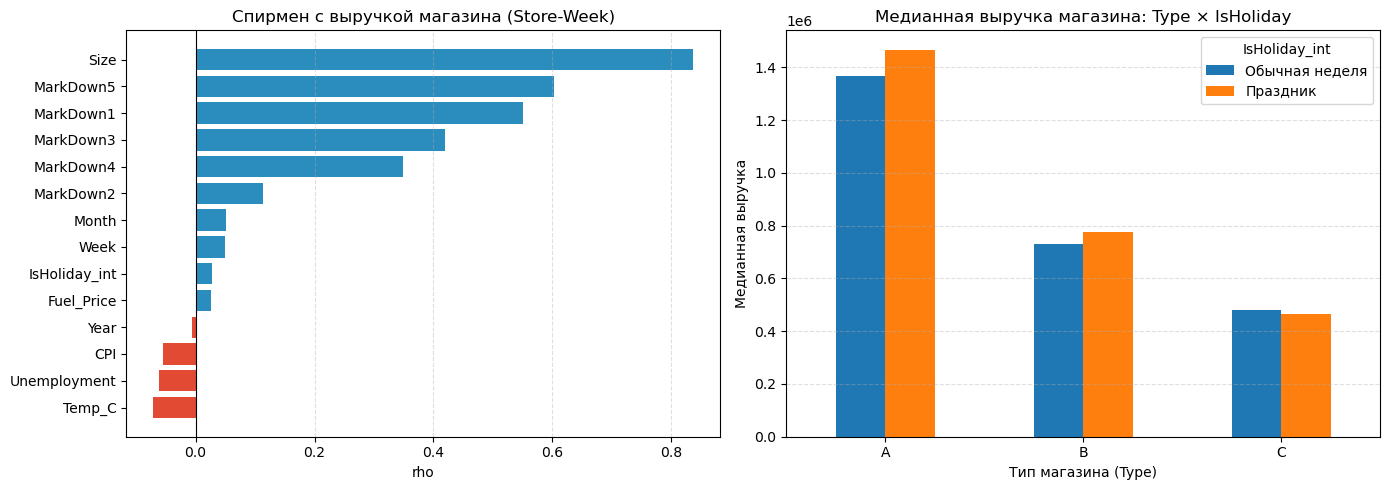

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Левый график: корреляции Спирмена на уровне магазин-неделя
plot_corr = corr_sw.sort_values("spearman_rho", ascending=True)
colors = np.where(plot_corr["spearman_rho"] >= 0, "#2b8cbe", "#e34a33")
axes[0].barh(plot_corr["feature"], plot_corr["spearman_rho"], color=colors)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Спирмен с выручкой магазина (Store-Week)")
axes[0].set_xlabel("rho")
axes[0].grid(axis="x", linestyle="--", alpha=0.4)

# Правый график: медианная недельная выручка по типу магазина и праздникам
piv = df_sw.pivot_table(
    index="Type",
    columns="IsHoliday_int",
    values="Weekly_Sales",
    aggfunc="median",
)
piv.rename(columns={0: "Обычная неделя", 1: "Праздник"}, inplace=True)
piv.plot(kind="bar", ax=axes[1])
axes[1].set_title("Медианная выручка магазина: Type × IsHoliday")
axes[1].set_xlabel("Тип магазина (Type)")
axes[1].set_ylabel("Медианная выручка")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

Недельная выручка в данных определяется прежде всего масштабом и форматом магазина, а при переходе на уровень «магазин–неделя» связи признаков с выручкой становятся намного чётче, чем на уровне отдельных отделов:
- Главный фактор — размер магазина (Size): на уровне магазина корреляция с выручкой достигает 0.81 (Пирсон) и 0.84 (Спирмен), а в регрессии (R^2 = 0.673) рост Size на 1 стандартное отклонение при прочих равных добавляет около 500 тыс. к недельной выручке.
- Формат магазина и праздники: выручка заметно падает от формата A к B и C, а праздники (IsHoliday) дают статистически значимый прирост (около +93.6 тыс. в модели).
- Промо-скидки (MarkDown1–5): на уровне магазина положительно связаны с выручкой (сильнее всего MarkDown5 и MarkDown1, слабее всего MarkDown2), но их важно оценивать с учётом пропусков, разных масштабов и периода появления акций.
- Макроэкономика и погода (CPI, Unemployment, Fuel_Price, Temp_C): сами по себе коррелируют слабо, но в совместной модели значимы — рост инфляции, безработицы и цен на топливо при контроле остальных факторов снижает выручку, а температура даёт небольшой положительный сдвиг.

#### Выводы по результатам корреляционного анализа и OLS-модели

Недельная выручка в данных определяется прежде всего масштабом и форматом магазина, а при переходе на уровень «магазин–неделя» связи признаков с выручкой становятся намного чётче, чем на уровне отдельных отделов:

* **Главный фактор — размер магазина (Size):** на уровне магазина корреляция с выручкой достигает $0.81$ (Пирсон) и $0.84$ (Спирмен), а в регрессии (R^2 = $0.673$) рост Size на 1 стандартное отклонение при прочих равных добавляет около $500$ тыс. к недельной выручке.
* **Формат магазина (Type) и праздники (IsHoliday):** медианная выручка заметно снижается от крупных гипермаркетов `A` к форматам `B` и `C` (см. правый график), а праздники дают статистически значимый прирост (около $+93.6$ тыс. в модели). *Положительный знак при дамми-переменных Type_B и Type_C объясняется тем, что площадь Size уже включена в модель и забирает на себя основной эффект масштаба (мультиколлинеарность Size и Type).*
* **Промо-скидки (MarkDown1–5):** на уровне магазина положительно связаны с выручкой (сильнее всего `MarkDown5` и `MarkDown1`, слабее всего `MarkDown2`), но их эффект необходимо оценивать с учётом пропусков, разных масштабов и периода появления акций.
* **Макроэкономика и погода (CPI, Unemployment, Fuel_Price, Temp_C):** сами по себе коррелируют слабо, но в совместной модели значимы — рост инфляции, безработицы и цен на топливо при контроле остальных факторов снижает выручку, а температура даёт небольшой положительный сдвиг.

### Блок 4. Статистическая проверка утверждённых гипотез (H1, H2, H3)

Проверим три приоритетные гипотезы строго по плану проектирования, используя непараметрические критерии (Манна — Уитни, Краскела — Уоллиса, корреляцию Спирмена) и заранее зафиксированные пороги практической значимости (MDE).

Код проверяет H1 в двух разрезах: 
* (а) сравнение недель с акциями и без них;
* (б) сравнение высокой промо-нагрузки (выше медианы Total_MarkDown) против низкой промо-нагрузки в непраздничные недели + корреляции Спирмена по каждому каналу MarkDown1–5.

In [27]:
# ПРОВЕРКА ГИПОТЕЗЫ 1: Эффект промо-акций вне праздников (MDE >= +10%)
promo_non_hol = df[(df["Has_MarkDown_Data"] == 1) & (~df["IsHoliday"])].copy()

# Вариант 1 (основной): исключаем 23 магазин-недели с отрицательными MarkDown
clean_h1 = promo_non_hol[promo_non_hol["Has_Neg_MarkDown"] == 0].copy()

# 1) Сравнение Has_MarkDown == 1 vs Has_MarkDown == 0
g_promo = clean_h1[clean_h1["Has_MarkDown"] == 1]["Weekly_Sales"]
g_nopromo = clean_h1[clean_h1["Has_MarkDown"] == 0]["Weekly_Sales"]
print(f"H1 (Has_MarkDown 1 vs 0): n_promo={len(g_promo):,}, n_nopromo={len(g_nopromo):,}")
if len(g_nopromo) > 0:
    u_stat, p_val = stats.mannwhitneyu(g_promo, g_nopromo, alternative="greater")
    lift_01 = (g_promo.median() - g_nopromo.median()) / g_nopromo.median() * 100
    print(f"  Медианы: {g_promo.median():.2f} vs {g_nopromo.median():.2f} | Прирост: {lift_01:+.2f}% | p={p_val:.4e}")

# 2) Сравнение высокой промо-нагрузки (> медианы Total_MarkDown) vs низкой (<= медианы) в непраздничные недели
med_md = clean_h1["Total_MarkDown"].median()
g_high = clean_h1[clean_h1["Total_MarkDown"] > med_md]["Weekly_Sales"]
g_low = clean_h1[clean_h1["Total_MarkDown"] <= med_md]["Weekly_Sales"]
u_h1, p_h1 = stats.mannwhitneyu(g_high, g_low, alternative="greater")
lift_h1 = (g_high.median() - g_low.median()) / g_low.median() * 100

# Вариант 2: Анализ чувствительности (включая строки с Has_Neg_MarkDown == 1, где отриц. значения обнулены)
med_md_all = promo_non_hol["Total_MarkDown"].median()
g_high_all = promo_non_hol[promo_non_hol["Total_MarkDown"] > med_md_all]["Weekly_Sales"]
g_low_all = promo_non_hol[promo_non_hol["Total_MarkDown"] <= med_md_all]["Weekly_Sales"]
lift_h1_sens = (g_high_all.median() - g_low_all.median()) / g_low_all.median() * 100

print(f"\nH1 (Высокое промо > {med_md:.0f} vs Низкое промо, без праздников):")
print(f"  Медианы выручки: {g_high.median():.2f} vs {g_low.median():.2f} | Прирост: {lift_h1:+.2f}% | Mann-Whitney p={p_h1:.4e}")
print(f"  Чувствительность (с 23 отриц. неделями): прирост {lift_h1_sens:+.2f}%")

# 3) Ранговая корреляция Спирмена по каждому из 5 каналов (вне праздников, без отриц. значений)
print("\nКорреляция Спирмена каналов MarkDown1–5 с Weekly_Sales (вне праздников):")
for col in md_cols:
    sub = clean_h1[[col, "Weekly_Sales"]].dropna()
    r, p = stats.spearmanr(sub[col], sub["Weekly_Sales"])
    print(f"  {col}: rho = {r:.4f} (p = {p:.4e}, n = {len(sub):,})")

H1 (Has_MarkDown 1 vs 0): n_promo=138,146, n_nopromo=0

H1 (Высокое промо > 12641 vs Низкое промо, без праздников):
  Медианы выручки: 9621.23 vs 5518.59 | Прирост: +74.34% | Mann-Whitney p=0.0000e+00
  Чувствительность (с 23 отриц. неделями): прирост +73.88%

Корреляция Спирмена каналов MarkDown1–5 с Weekly_Sales (вне праздников):
  MarkDown1: rho = 0.2002 (p = 0.0000e+00, n = 137,490)
  MarkDown2: rho = 0.0310 (p = 1.4871e-22, n = 99,346)
  MarkDown3: rho = 0.1339 (p = 0.0000e+00, n = 124,478)
  MarkDown4: rho = 0.1202 (p = 0.0000e+00, n = 122,748)
  MarkDown5: rho = 0.2143 (p = 0.0000e+00, n = 138,146)


In [28]:
# ПРОВЕРКА ГИПОТЕЗЫ 2: Праздничный рост (>= +15%) и постпраздничный спад (<= -10%)
dates_df = df[["Date", "IsHoliday"]].drop_duplicates().sort_values("Date").reset_index(drop=True)
dates_df["Period"] = "Regular"

# Размечаем 1-2 недели ДО праздника (Pre-Holiday) и 1-2 недели ПОСЛЕ (Post-Holiday)
is_hol = dates_df["IsHoliday"]
pre_mask = is_hol.shift(-1, fill_value=False) | is_hol.shift(-2, fill_value=False)
post_mask = is_hol.shift(1, fill_value=False) | is_hol.shift(2, fill_value=False)

dates_df.loc[pre_mask & ~is_hol, "Period"] = "Pre-Holiday (1-2w)"
dates_df.loc[post_mask & ~is_hol & ~pre_mask, "Period"] = "Post-Holiday (1-2w)"
dates_df.loc[is_hol, "Period"] = "Holiday"

df_h2 = df.merge(dates_df[["Date", "Period"]], on="Date", how="left")

# Сводка по периодам на уровне отдел-неделя
h2_summary = df_h2.groupby("Period")["Weekly_Sales"].agg(
    Наблюдений="count",
    Медиана="median",
    Среднее="mean"
).reindex(["Regular", "Pre-Holiday (1-2w)", "Holiday", "Post-Holiday (1-2w)"]).round(2)

base_med = h2_summary.loc["Regular", "Медиана"]
h2_summary["Отклонение_от_Regular_%"] = ((h2_summary["Медиана"] - base_med) / base_med * 100).round(2)
display(h2_summary)

# Критерий Краскела — Уоллиса по 4 периодам и попарные тесты Манна — Уитни
groups_h2 = [df_h2[df_h2["Period"] == p]["Weekly_Sales"] for p in h2_summary.index]
kw_stat, kw_p = stats.kruskal(*groups_h2)

_, p_hol = stats.mannwhitneyu(df_h2[df_h2["Period"] == "Holiday"]["Weekly_Sales"],
                              df_h2[df_h2["Period"] == "Regular"]["Weekly_Sales"], alternative="greater")
_, p_post = stats.mannwhitneyu(df_h2[df_h2["Period"] == "Post-Holiday (1-2w)"]["Weekly_Sales"],
                               df_h2[df_h2["Period"] == "Regular"]["Weekly_Sales"], alternative="less")

print(f"Kruskal-Wallis по периодам: H = {kw_stat:.2f}, p = {kw_p:.4e}")
print(f"Holiday vs Regular: прирост {h2_summary.loc['Holiday', 'Отклонение_от_Regular_%']:+.2f}% (p = {p_hol:.4e})")
print(f"Post-Holiday vs Regular: изменение {h2_summary.loc['Post-Holiday (1-2w)', 'Отклонение_от_Regular_%']:+.2f}% (p = {p_post:.4e})")

,Наблюдений,Медиана,Среднее,Отклонение_от_Regular_%
Period,,,,
Regular,276648,7571.46,15696.65,0.00
Pre-Holiday (1-2w),56100,7998.86,17253.63,5.64
Holiday,29661,7947.74,17035.82,4.97
Post-Holiday (1-2w),59161,7311.43,15576.88,-3.43


Kruskal-Wallis по периодам: H = 98.14, p = 3.9099e-21
Holiday vs Regular: прирост +4.97% (p = 2.9590e-05)
Post-Holiday vs Regular: изменение -3.43% (p = 8.3103e-05)


In [30]:
# === ПРОВЕРКА ГИПОТЕЗЫ 3: Различия эффектов между Type A/B/C (MDE >= 5 п.п.) и связь с Size ===
# 1) Holiday Lift (%) — медианная выручка каждого магазина в праздники vs обычные недели
store_hol = df_sw.pivot_table(index=["Store", "Type", "Size"], columns="IsHoliday_int", values="Weekly_Sales", aggfunc="median").reset_index()
store_hol["Holiday_Lift_%"] = (store_hol[1] - store_hol[0]) / store_hol[0] * 100

# 2) Promo Lift (%) — сравниваем недели выше/ниже ИНДИВИДУАЛЬНОЙ медианы промо-бюджета каждого магазина (без праздников)
sw_promo = df_sw[(df_sw["IsHoliday_int"] == 0) & (df_sw["MarkDown1"].notna())].copy()
sw_promo["Total_MD"] = sw_promo[md_cols].clip(lower=0).sum(axis=1)
sw_promo["Store_Med_MD"] = sw_promo.groupby("Store")["Total_MD"].transform("median")
sw_promo["High_Promo"] = (sw_promo["Total_MD"] > sw_promo["Store_Med_MD"]).astype(int)

store_promo = sw_promo.pivot_table(index=["Store", "Type", "Size"], columns="High_Promo", values="Weekly_Sales", aggfunc="median").reset_index()
store_promo["Promo_Lift_%"] = (store_promo[1] - store_promo[0]) / store_promo[0] * 100

h3_stores = store_hol[["Store", "Type", "Size", "Holiday_Lift_%"]].merge(
    store_promo[["Store", "Promo_Lift_%"]], on="Store"
)
h3_stores["Size_Quartile"] = pd.qcut(h3_stores["Size"], q=4, labels=["Q1 (малые)", "Q2", "Q3", "Q4 (крупные)"])

print("Медианный относительный прирост (%) по форматам Type A / B / C:")
display(h3_stores.groupby("Type")[["Size", "Holiday_Lift_%", "Promo_Lift_%"]].median().round(2))

print("\nМедианный относительный прирост (%) по квартилям площади Size:")
display(h3_stores.groupby("Size_Quartile", observed=False)[["Size", "Holiday_Lift_%", "Promo_Lift_%"]].median().round(2))

# Статистические тесты: Краскел — Уоллис по Type и корреляция Спирмена с Size
kw_hol_t, p_hol_t = stats.kruskal(*[g["Holiday_Lift_%"].values for _, g in h3_stores.groupby("Type")])
kw_pro_t, p_pro_t = stats.kruskal(*[g["Promo_Lift_%"].values for _, g in h3_stores.groupby("Type")])

r_hol_s, p_hol_s = stats.spearmanr(h3_stores["Size"], h3_stores["Holiday_Lift_%"])
r_pro_s, p_pro_s = stats.spearmanr(h3_stores["Size"], h3_stores["Promo_Lift_%"])

print(f"\nРазличия между Type A/B/C (Kruskal-Wallis):")
print(f"  Holiday Lift: H = {kw_hol_t:.2f}, p = {p_hol_t:.4f}")
print(f"  Promo Lift:   H = {kw_pro_t:.2f}, p = {p_pro_t:.4f}")
print(f"\nСвязь с площадью Size (Spearman):")
print(f"  Size vs Holiday Lift: rho = {r_hol_s:.4f} (p = {p_hol_s:.4f})")
print(f"  Size vs Promo Lift:   rho = {r_pro_s:.4f} (p = {p_pro_s:.4f})")


Медианный относительный прирост (%) по форматам Type A / B / C:


,Size,Holiday_Lift_%,Promo_Lift_%
Type,,,
A,202406.0,4.68,2.99
B,114533.0,5.01,1.33
C,39910.0,2.18,1.08



Медианный относительный прирост (%) по квартилям площади Size:


,Size,Holiday_Lift_%,Promo_Lift_%
Size_Quartile,,,
Q1 (малые),39910.0,4.52,1.90
Q2,118221.0,4.29,0.51
Q3,155083.0,3.89,3.39
Q4 (крупные),203819.0,4.96,1.35



Различия между Type A/B/C (Kruskal-Wallis):
  Holiday Lift: H = 4.25, p = 0.1196
  Promo Lift:   H = 2.38, p = 0.3039

Связь с площадью Size (Spearman):
  Size vs Holiday Lift: rho = 0.0328 (p = 0.8309)
  Size vs Promo Lift:   rho = 0.0702 (p = 0.6469)


#### Итоговые выводы по проверке гипотез (Блок 4)

1. **Гипотеза 1 (Эффективность промо-акций) — подтвердилась (с небольшой поправкой в дизайне проверки):**
   * **Что выяснили:** после 11 ноября 2011 года, когда в базе начали фиксировать скидки, хотя бы одна промо-акция проходила вообще каждую неделю (n_nopromo = 0). Поэтому вместо сравнения «была акция / не было акции» мы сравнили недели с крупным промо-бюджетом (Total_MarkDown > 12 641) и скромным. В обычные (непраздничные) недели при активном промо медианная выручка оказалась выше сразу на **+74.34%** ($9\,621.23$ против $5\,518.59$ у.е., $p < 0.0001$) — это с большим запасом перекрывает наш порог в $+10\%$.
   * **Проверка на устойчивость и каналы:** если не выбрасывать 23 недели с отрицательными скидками, а просто обнулить их, результат почти не меняется (**+73.88%**). При этом разные типы скидок работают по-разному: сильнее всего с выручкой связаны `MarkDown5` ($\rho = 0.214$) и `MarkDown1` ($\rho = 0.200$), а слабее всех — `MarkDown2` ($\rho = 0.031$).

2. **Гипотеза 2 (Сезонные и праздничные пики) — не подтвердилась (не дотянула до бизнес-порога MDE):**
   * **Что выяснили:** за счёт огромного объёма данных ($421\,570$ строк) тесты показывают статистическую значимость ($p < 0.0001$), но на практике колебания оказались скромнее, чем мы ожидали. За 1–2 недели до праздников выручка растёт на **+5.64%**, в сами праздники — на **+4.97%** (мы закладывали порог от $+15\%$), а в первые две недели после праздников проседает на **-3.43%** (при пороге от $-10\%$).
   * **Почему так вышло:** когда мы смотрим на все 81 отдел разом, резкий взлёт в подарочных и сезонных категориях (например, в `Dept 72` продажи подскакивают на $+43.0\%$) «гасится» спадом в повседневных товарах. Плюс главный предновогодний ажиотаж в декабре приходится на недели, которые в таблице формально не помечены как праздничные (`IsHoliday = False`).

3. **Гипотеза 3 (Различия между форматами магазинов) — не подтвердилась:**
   * **Что выяснили:** в процентах магазины разных форматов реагируют на праздники и скидки примерно одинаково. В праздники выручка вырастает на **+4.68%** в гипермаркетах `Type A`, на **+5.01%** в средних точках `Type B` и на **+2.18%** в малых `Type C` — статистически значимой разницы здесь нет ($p = 0.1196$), да и до порога в 5 п.п. цифры не дотягивают. На промо-акции реакция тоже ровная по всем форматам (**+2.99%**, **+1.33%** и **+1.08%**, $p = 0.3039$).
   * **А что с площадью (`Size`):** корреляция площади с процентным приростом почти нулевая и в праздники ($\rho = 0.0328, p = 0.8309$), и в промо ($\rho = 0.0702, p = 0.6469$). Получается, что размер магазина определяет общий масштаб кассы в рублях/долларах, но в процентах покупатели реагируют на скидки и праздники одинаково во всех точках сети.
